Coffee Shop Sales

Transaction records for Maven Roasters, a fictitious coffee shop operating out of three NYC locations. Dataset includes the transaction date, timestamp and location, along with product-level details.

Recommended Analysis

1 - How have Maven Roasters sales trended over time?

2 - Which days of the week tend to be busiest, and why do you think that's the case?

3 - Which products are sold most and least often? Which drive the most revenue for the business?

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
coffee = pd.read_excel('data/Coffee Shop Sales.xlsx')

In [3]:
coffee.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [4]:
coffee.isnull().sum()

transaction_id      0
transaction_date    0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

In [5]:
coffee.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null  object        
 10  product_detail    149116 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(4), object(5)
memory usage: 12.5+ MB


In [6]:
coffee['transaction_time'] = coffee['transaction_time'].astype(str)
coffee['transaction_time'] = pd.to_timedelta(coffee['transaction_time'])

In [7]:
coffee['sales'] = coffee['transaction_qty'] * coffee['unit_price']

In [8]:
coffee['datetime'] = coffee['transaction_date'] + coffee['transaction_time']

In [9]:
coffee.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,sales,datetime
0,1,2023-01-01,0 days 07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg,6.0,2023-01-01 07:06:11
1,2,2023-01-01,0 days 07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2,2023-01-01 07:08:56
2,3,2023-01-01,0 days 07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,9.0,2023-01-01 07:14:04
3,4,2023-01-01,0 days 07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm,2.0,2023-01-01 07:20:24
4,5,2023-01-01,0 days 07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2,2023-01-01 07:22:41


In [10]:
coffee.describe()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,product_id,unit_price,sales,datetime
count,149116.000000,149116,149116,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116
mean,74737.371872,2023-04-15 11:50:32.173609984,0 days 12:14:15.815794415,1.438276,5.342063,47.918607,3.382219,4.686367,2023-04-16 00:04:47.989404160
min,1.000000,2023-01-01 00:00:00,0 days 06:00:00,1.000000,3.000000,1.000000,0.800000,0.800000,2023-01-01 07:06:11
25%,37335.750000,2023-03-06 00:00:00,0 days 09:05:10.500000,1.000000,3.000000,33.000000,2.500000,3.000000,2023-03-06 13:37:08
50%,74727.500000,2023-04-24 00:00:00,0 days 11:15:28,1.000000,5.000000,47.000000,3.000000,3.750000,2023-04-24 08:24:32.500000
75%,112094.250000,2023-05-30 00:00:00,0 days 15:25:57,2.000000,8.000000,60.000000,3.750000,6.000000,2023-05-30 07:16:13
max,149456.000000,2023-06-30 00:00:00,0 days 20:59:32,8.000000,8.000000,87.000000,45.000000,360.000000,2023-06-30 20:57:19
std,43153.600016,NaN,0 days 03:45:57.901686173,0.542509,2.074241,17.930020,2.658723,4.227099,NaN


In [11]:
shop_location = coffee.groupby('store_location').agg(
    {
        'sales':'sum',
        'transaction_id':'count'
    })
shop_location

,sales,transaction_id
store_location,,
Astoria,232243.91,50599
Hell's Kitchen,236511.17,50735
Lower Manhattan,230057.25,47782


Prepare data for visualization

In [12]:
daily_sales_by_location = coffee.groupby(['transaction_date','store_location'])['sales'].sum().unstack()

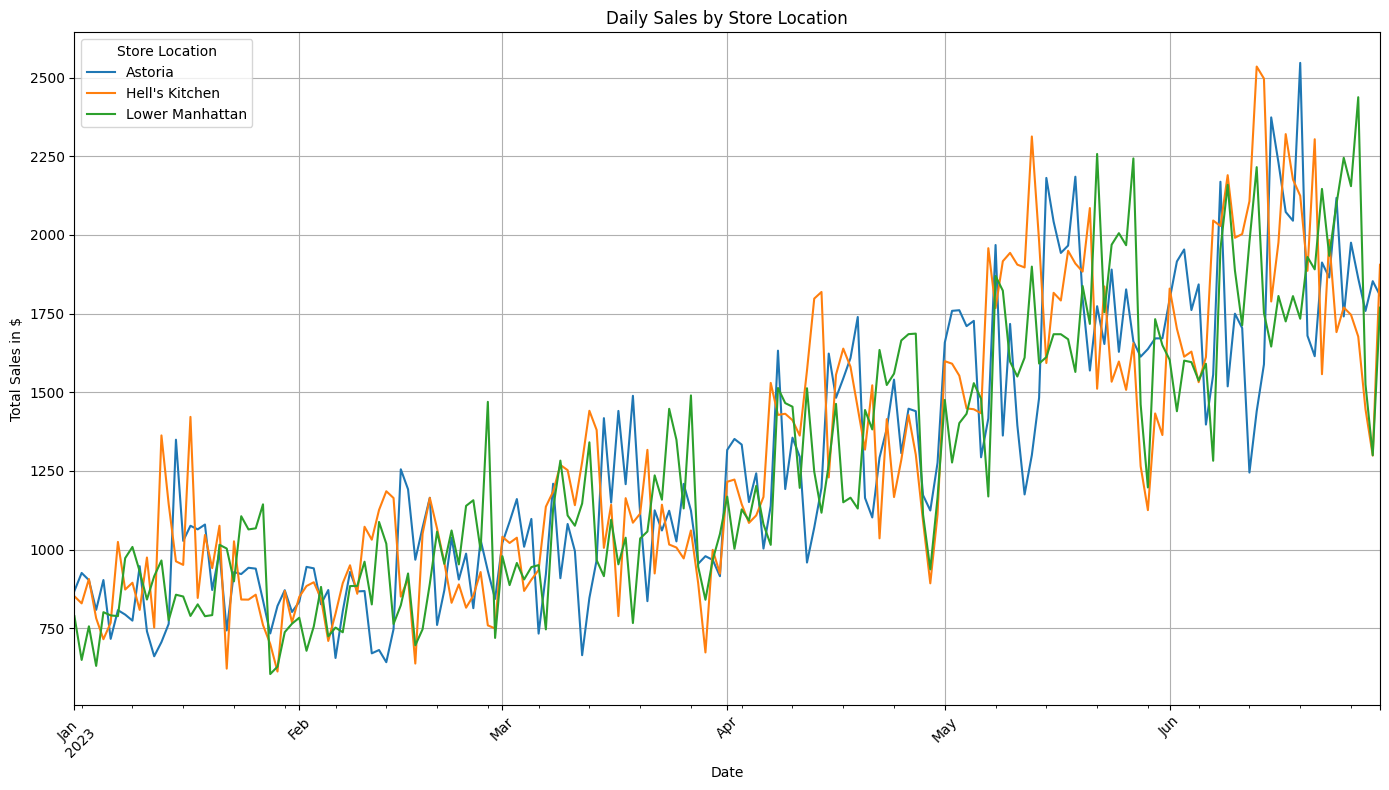

In [13]:
daily_sales_by_location.plot(figsize=(14,8), title='Daily Sales by Store Location')

plt.xlabel('Date')
plt.ylabel('Total Sales in $')
plt.legend(title='Store Location')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

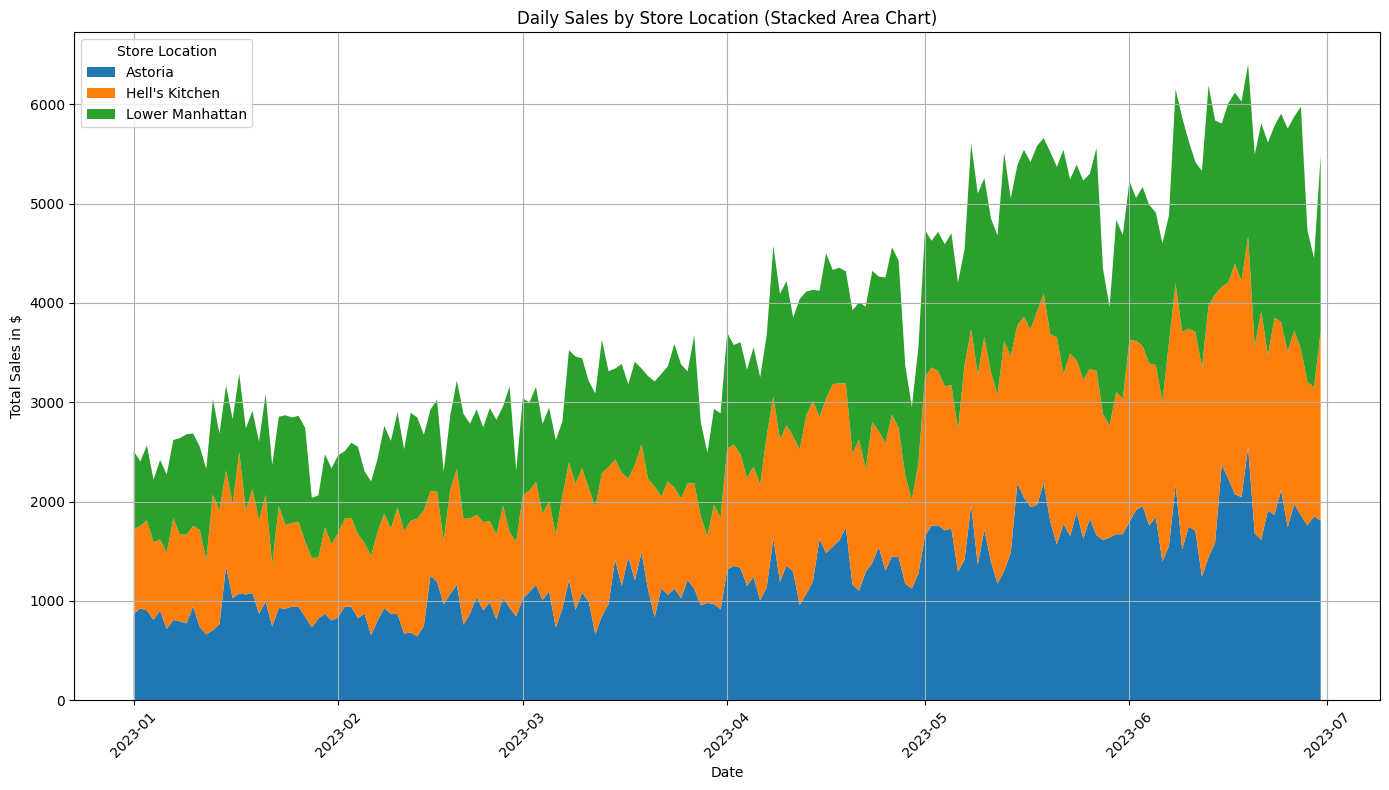

In [14]:
plt.figure(figsize=(14,8))

plt.stackplot(daily_sales_by_location.index, daily_sales_by_location.T, labels=daily_sales_by_location.columns)

plt.title('Daily Sales by Store Location (Stacked Area Chart)')
plt.xlabel('Date')
plt.ylabel('Total Sales in $')
plt.legend(title='Store Location', loc='upper left')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

The total daily sales rised significantly with some days experiencing high sales than others. Sales seem to increased towards the end of the analysis period with daily sales consistently high in June compared to January.

for daily sales

In [15]:
daily_sales = coffee.groupby('transaction_date')['sales'].sum().reset_index()

for weekly sales

In [16]:
coffee['day_of_week'] = coffee['datetime'].dt.day_name()

weekly_sales = coffee.groupby('day_of_week')['sales'].sum().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
).reset_index()

In [44]:
weekly_sales#.sort_values('sales', ascending=False)

,day_of_week,sales
0,Monday,101677.28
1,Tuesday,99455.94
2,Wednesday,100313.54
3,Thursday,100767.78
4,Friday,101373.00
5,Saturday,96894.48
6,Sunday,98330.31


for monthly sales

In [18]:
coffee['month'] = coffee['datetime'].dt.to_period('M')
monthly_sales = coffee.groupby('month')['sales'].sum().reset_index()

In [41]:
monthly_sales

,month,sales
0,2023-01,81677.74
1,2023-02,76145.19
2,2023-03,98834.68
3,2023-04,118941.08
4,2023-05,156727.76
5,2023-06,166485.88


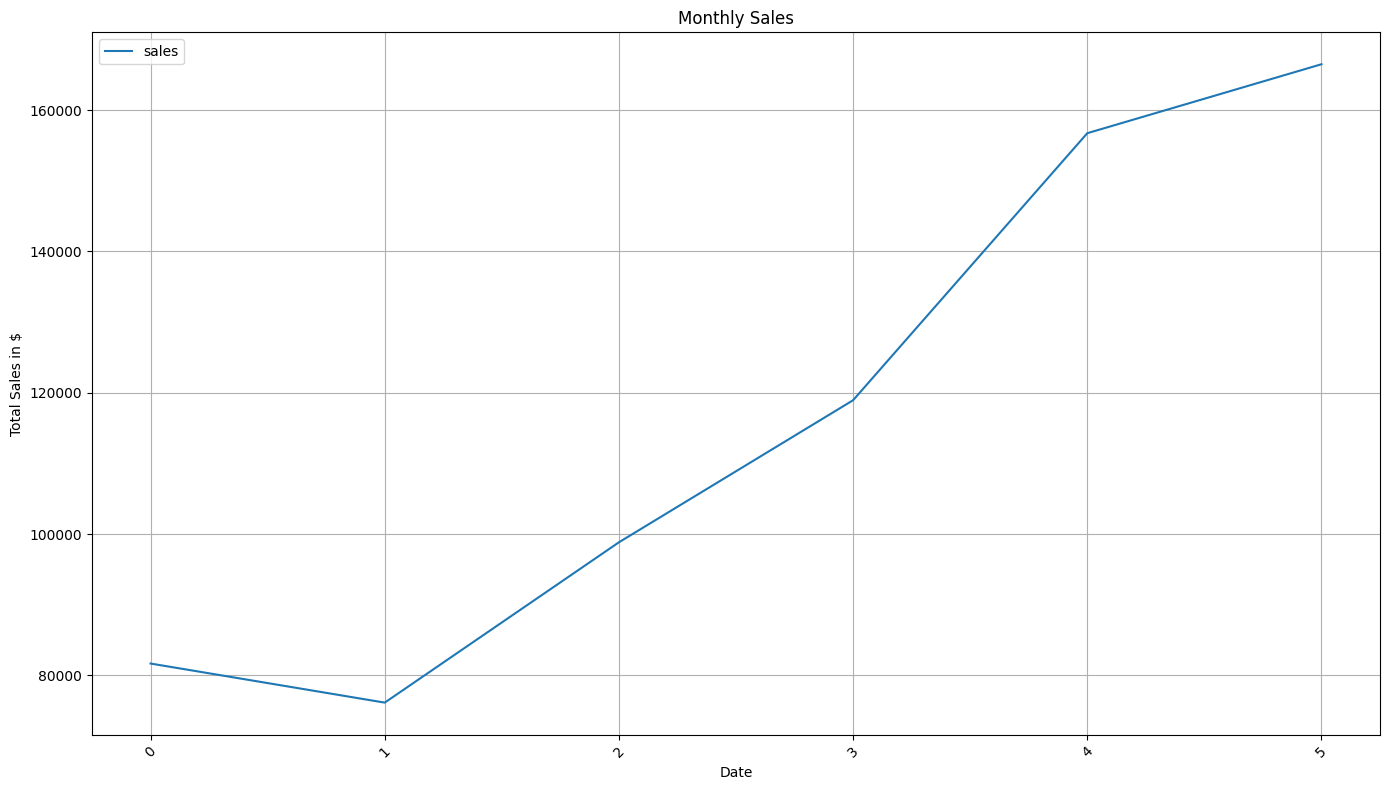

In [37]:
monthly_sales.plot(figsize=(14,8), title='Monthly Sales')

plt.xlabel('Date')
plt.ylabel('Total Sales in $')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Monthly sales trend have been increasing month over month from January to June. June has the highest total sales over the observed period.

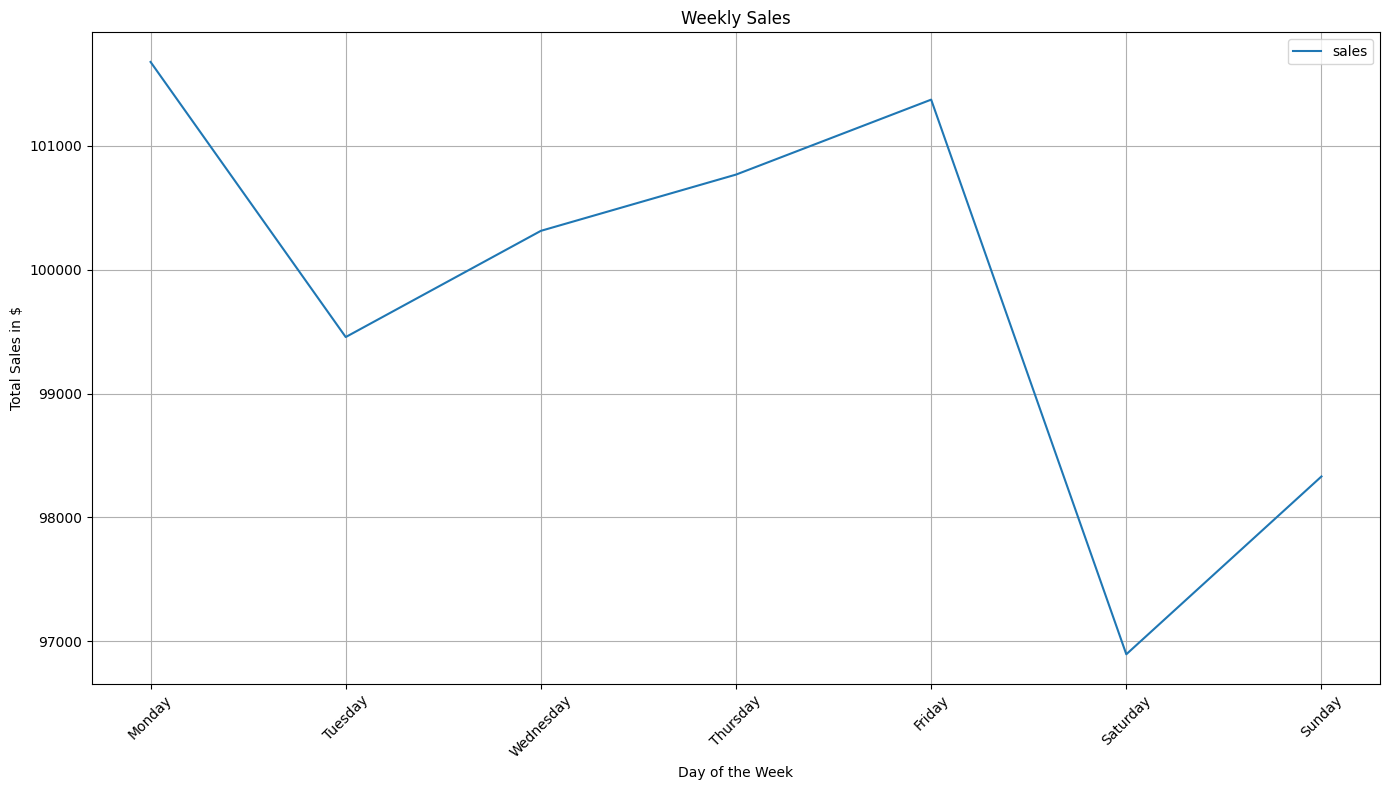

In [25]:
weekly_sales.plot(x='day_of_week', y='sales', figsize=(14,8), title='Weekly Sales')

plt.xlabel('Day of the Week')
plt.ylabel('Total Sales in $')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Sales are relatively consistent throughout the week. Monday has the highest total sales followed closely by Friday, Thursday, Wednesday, and Tuesday. Saturday and Sunday have slightly lower sales than the rest of the week.

In [21]:
weekly_sale_perloc = coffee.groupby(['day_of_week','store_location'])['sales'].sum().unstack()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekly_sale_perloc = weekly_sale_perloc.reindex(days_order)
weekly_sale_perloc

store_location,Astoria,Hell's Kitchen,Lower Manhattan
day_of_week,,,
Monday,33928.29,33389.51,34359.48
Tuesday,31816.76,34846.47,32792.71
Wednesday,34244.63,33779.09,32289.82
Thursday,34140.37,33468.06,33159.35
Friday,33472.75,34743.18,33157.07
Saturday,31845.93,32599.23,32449.32
Sunday,32795.18,33685.63,31849.50


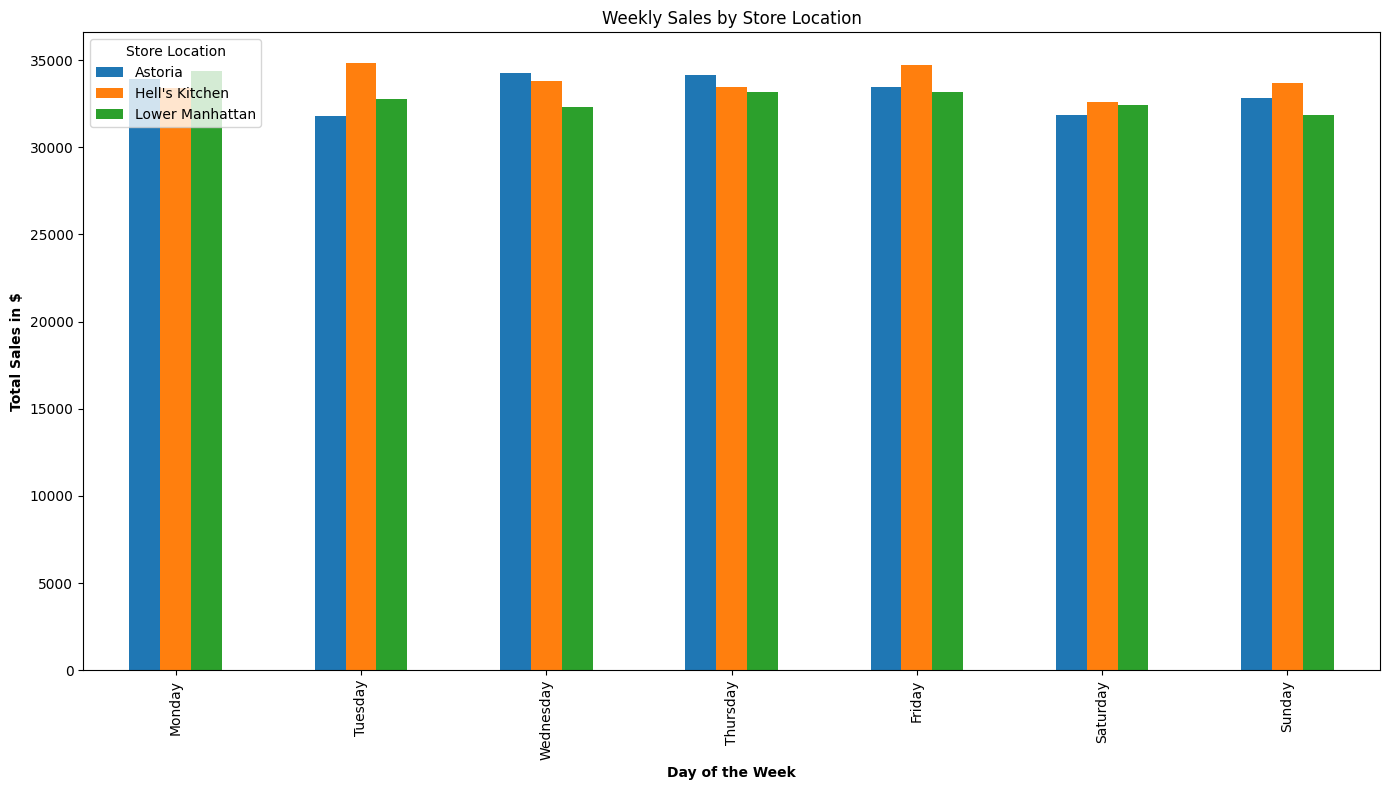

In [22]:
weekly_sale_perloc[['Astoria',"Hell's Kitchen",'Lower Manhattan']].plot(kind='bar', figsize=(14, 8))

plt.xlabel('Day of the Week', fontweight='bold')
plt.ylabel('Total Sales in $', fontweight='bold')
plt.title('Weekly Sales by Store Location')
plt.legend(title='Store Location', loc='upper left')

plt.tight_layout()
plt.show()

In [24]:
coffee_category = coffee.groupby('product_category').agg(
    {
        'sales':'sum',
        'transaction_id':'count'
}).sort_values('sales', ascending=False)

coffee_category

,sales,transaction_id
product_category,,
Coffee,269952.45,58416
Tea,196405.95,45449
Bakery,82315.64,22796
Drinking Chocolate,72416.00,11468
Coffee beans,40085.25,1753
Branded,13607.00,747
Loose Tea,11213.60,1210
Flavours,8408.80,6790
Packaged Chocolate,4407.64,487


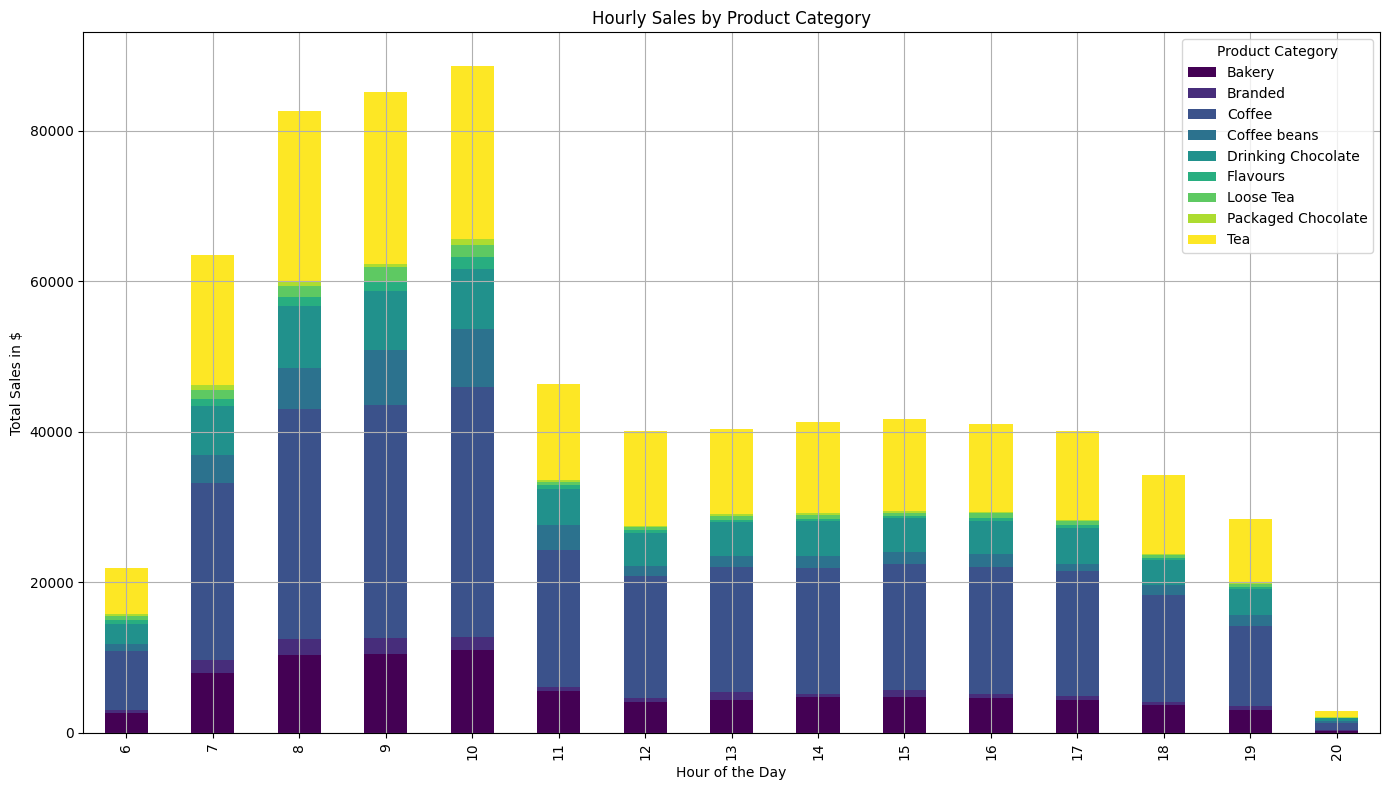

In [26]:
coffee['hour'] = coffee['datetime'].dt.hour

hourly_sales_by_product = coffee.groupby(['hour','product_category'])['sales'].sum().unstack()
hourly_sales_by_product.plot(kind='bar', stacked=True, figsize=(14,8), colormap='viridis')

plt.title('Hourly Sales by Product Category')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Sales in $')
plt.legend(title='Product Category', loc='upper right')
plt.grid(True)
plt.tight_layout()

plt.show()

In [27]:
coffee_category['avg_sales'] = coffee_category['sales']/coffee_category['transaction_id']

coffee_category

,sales,transaction_id,avg_sales
product_category,,,
Coffee,269952.45,58416,4.621207
Tea,196405.95,45449,4.321458
Bakery,82315.64,22796,3.610969
Drinking Chocolate,72416.00,11468,6.314615
Coffee beans,40085.25,1753,22.866657
Branded,13607.00,747,18.215529
Loose Tea,11213.60,1210,9.267438
Flavours,8408.80,6790,1.238409
Packaged Chocolate,4407.64,487,9.050595


In [28]:
sales_by_product = coffee.groupby('product_type').agg(
    {
        'sales':'sum',
        'unit_price':'mean'
    }
).sort_values('sales', ascending=False)

sales_by_product

,sales,unit_price
product_type,,
Barista Espresso,91406.20,3.655200
Brewed Chai tea,77081.95,2.936993
Hot chocolate,72416.00,4.148827
Gourmet brewed coffee,70034.60,2.696641
Brewed Black tea,47932.00,2.744670
Brewed herbal tea,47539.50,2.744731
Premium brewed coffee,38781.15,3.122452
Organic brewed coffee,37746.50,2.898021
Scone,36866.12,3.534638


In [29]:
product_sales_coffee = coffee.groupby(['product_category','product_type'])['sales'].sum().reset_index()
product_sales_coffee

,product_category,product_type,sales
0,Bakery,Biscotti,19793.53
1,Bakery,Pastry,25655.99
2,Bakery,Scone,36866.12
3,Branded,Clothing,6163.00
4,Branded,Housewares,7444.00
5,Coffee,Barista Espresso,91406.20
6,Coffee,Drip coffee,31984.00
7,Coffee,Gourmet brewed coffee,70034.60
8,Coffee,Organic brewed coffee,37746.50
9,Coffee,Premium brewed coffee,38781.15


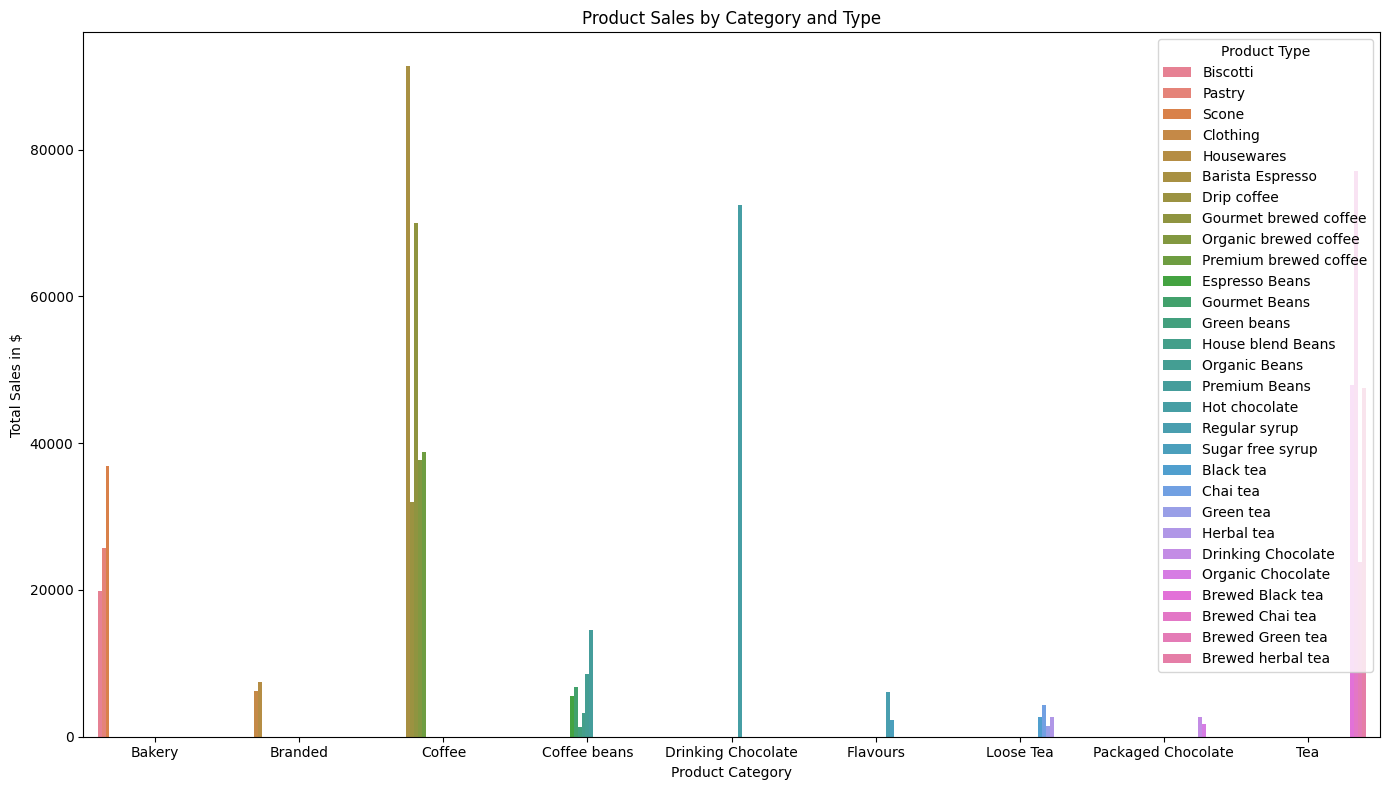

In [33]:
plt.figure(figsize=(14,8))
sns.barplot(data=product_sales_coffee, x='product_category', y='sales', hue='product_type')

plt.title('Product Sales by Category and Type')
plt.xlabel('Product Category')
plt.ylabel('Total Sales in $')
plt.legend(title='Product Type', loc='upper right')
plt.tight_layout()

plt.show()


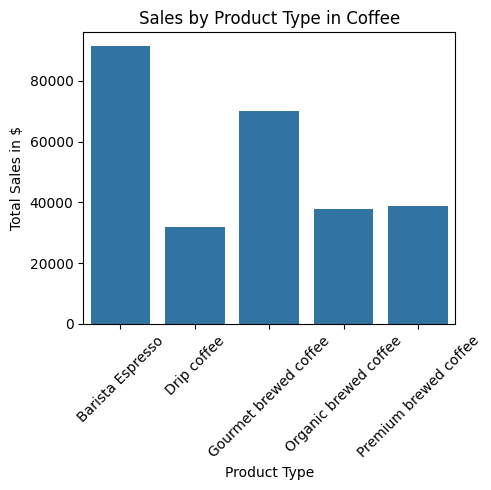

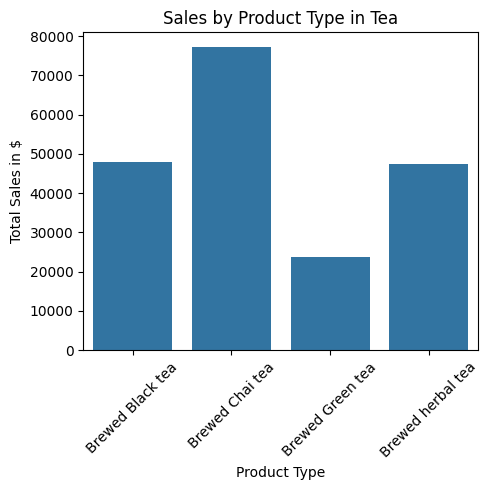

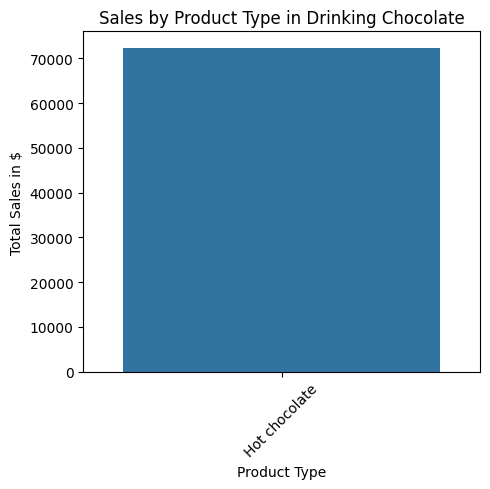

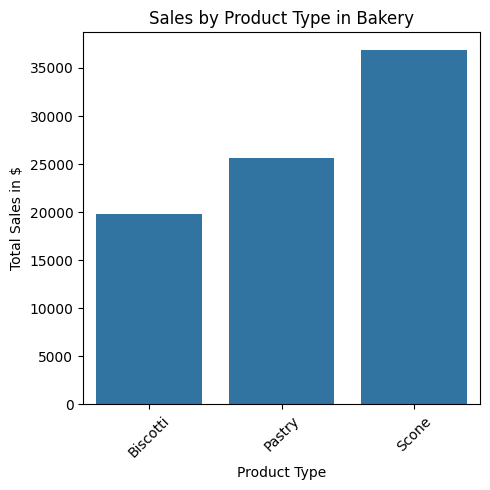

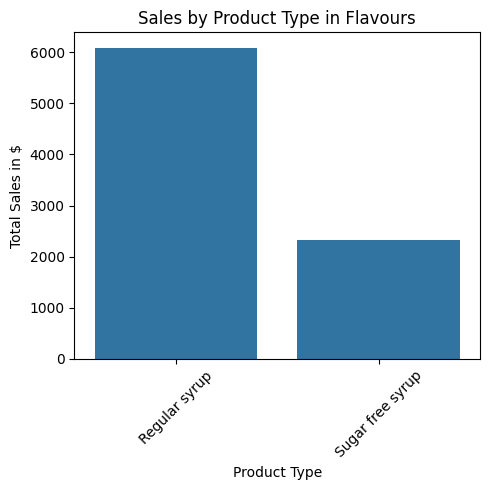

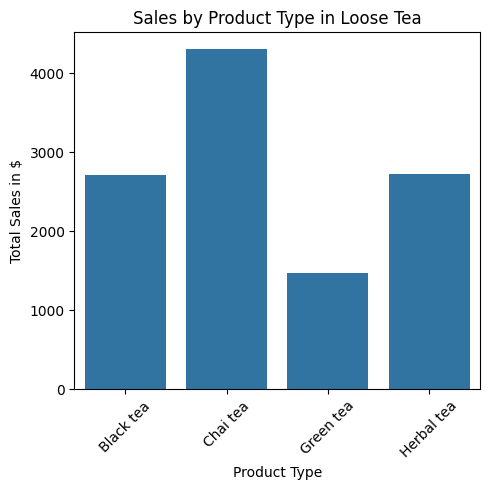

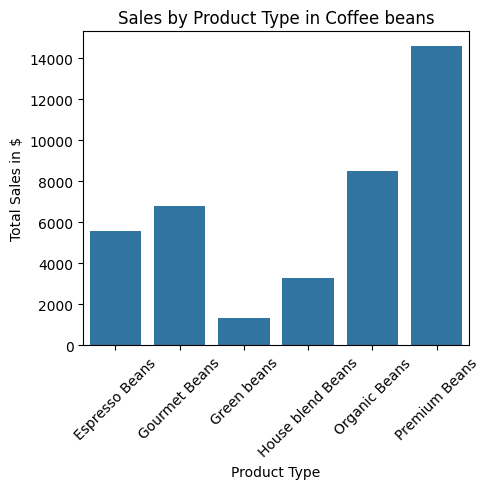

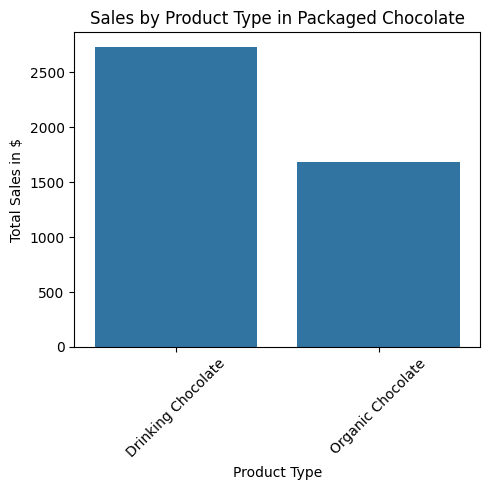

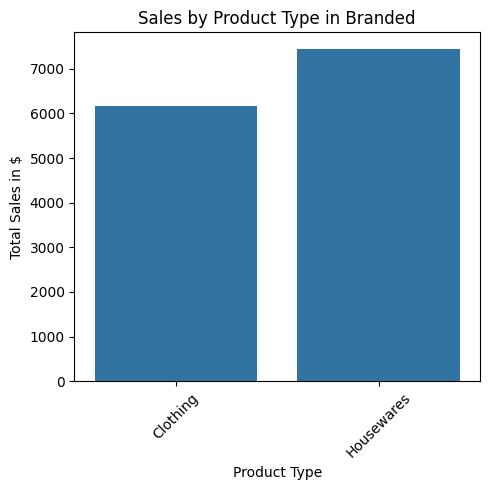

In [34]:
categories = coffee['product_category'].unique()

for category in categories:
    plt.figure(figsize=(5,5))
    category_data = product_sales_coffee[product_sales_coffee['product_category'] == category]
    sns.barplot(data=category_data, x='product_type', y='sales')
    
    plt.title(f'Sales by Product Type in {category}')
    plt.xlabel('Product Type')
    plt.ylabel('Total Sales in $')
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()

In [35]:
hourly_sales_by_location = coffee.groupby(['store_location','hour'])['sales'].sum().reset_index()
hourly_sales_by_location

,store_location,hour,sales
0,Astoria,7,19028.80
1,Astoria,8,22805.90
2,Astoria,9,23183.57
3,Astoria,10,24426.12
4,Astoria,11,15498.13
5,Astoria,12,15681.20
6,Astoria,13,15947.87
7,Astoria,14,15175.27
8,Astoria,15,15651.95
9,Astoria,16,16110.85


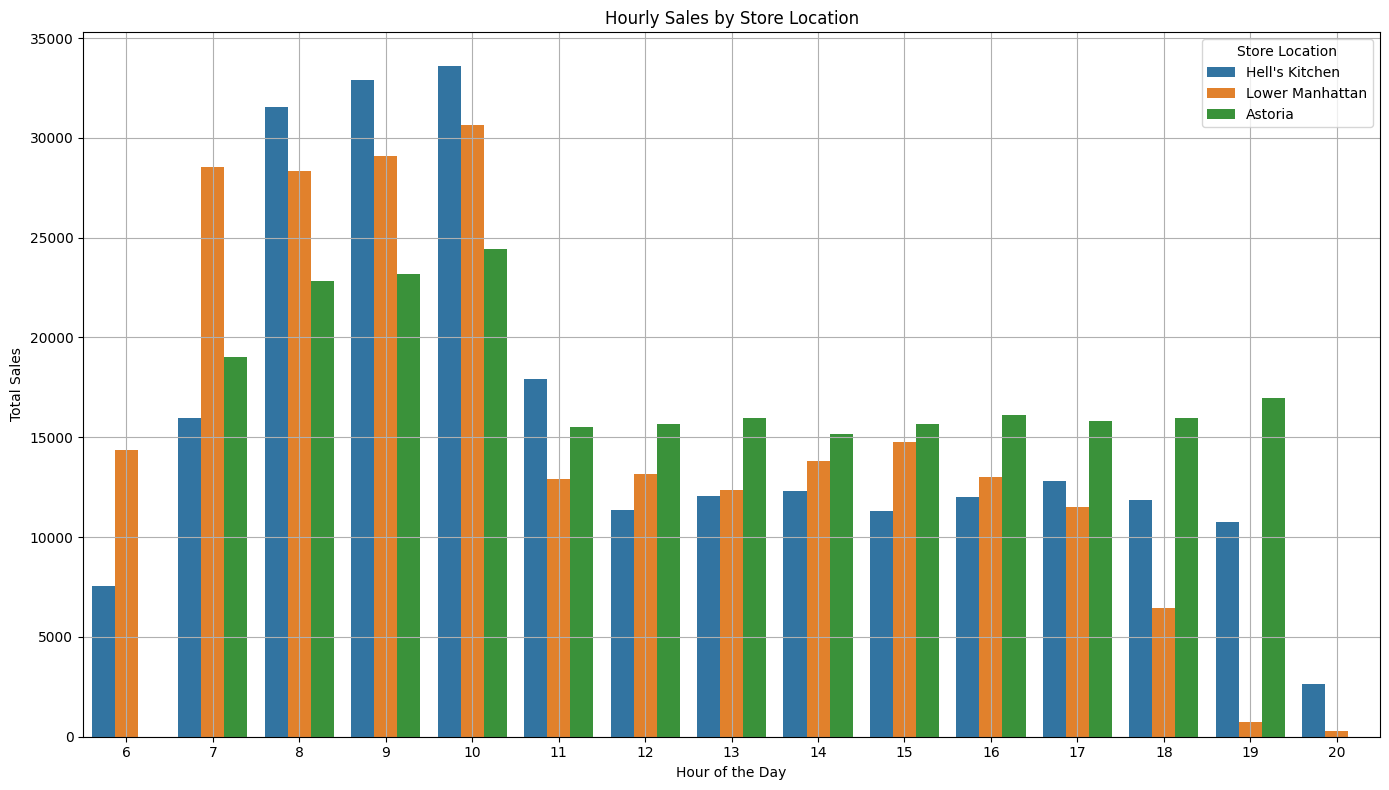

In [36]:
plt.figure(figsize=(14,8))
sns.barplot(data=hourly_sales_by_location, x='hour', y='sales', hue='store_location')

plt.title('Hourly Sales by Store Location')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Sales')
plt.legend(title='Store Location', loc='upper right')
plt.grid(True)
plt.tight_layout()

plt.show()